# Segmentação de Clientes para CRM | Olist

## Resumo executivo

**97% dos clientes compraram uma única vez. A verba de CRM deve ir para gerar a segunda compra, começando pelos 7.145 clientes de prioridade alta.**

- **O problema:** de 93.104 clientes (jan/2017 a ago/2018), apenas 3% voltaram a comprar. Esses recorrentes representam 5,6% da receita.
- **Por que a segunda compra importa:** quem volta gasta o dobro no período (R\$ 309 vs R\$ 161), não por comprar mais caro (R\$ 146 vs R\$ 161 por pedido), mas por comprar de novo.
- **Quem priorizar:** clientes de compra única com última compra há até 92 dias e gasto acima de R\$ 132. É um grupo com recência mediana de 43 dias e gasto semelhante ao dos recorrentes.
- **Retorno esperado (cenário moderado):** R\$ 10,05 por cliente impactado na prioridade alta, 5x a prioridade baixa. Prioridades alta e média somam cerca de R\$ 163 mil em receita potencial.
- **Entrega:** lista de 25.232 clientes (prioridades alta e média), ordenada por potencial, em `processed/lista_campanha_segunda_compra.csv`.

**Limitações:** taxas de conversão são hipóteses; valores são receita, não margem; o ganho real deve ser medido com grupo de controle (teste A/B).

## Compreensão do Negócio

**Contexto (cenário fictício):** a gerência de CRM tem verba para campanhas de relacionamento no próximo trimestre e quer saber em quem investir primeiro.

**Pergunta de negócio:** como segmentar a base de clientes para direcionar as campanhas?

**Critério de sucesso:** segmentos acionáveis, com tamanho e valor de cada grupo, e uma recomendação de onde alocar a verba.

**Abordagem:** segmentação RFM (Recência, Frequência, Monetário), calculada manualmente com pandas.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Mostrar todas as colunas e números sem notação científica
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Caminhos do projeto
PASTA_RAIZ = Path(r"C:\Users\fabio\analytics\project\olist_brasil")
PASTA_RAW = PASTA_RAIZ / "raw"
PASTA_PROCESSED = PASTA_RAIZ / "processed"
PASTA_OUTPUT = PASTA_RAIZ / "output"

# Checagem dos arquivos
arquivos = sorted(PASTA_RAW.glob("*.csv"))
print(f"Arquivos encontrados: {len(arquivos)}")
for arq in arquivos:
    print(f" - {arq.name} ({arq.stat().st_size / 1024:.2f} KB)")

Arquivos encontrados: 9
 - olist_customers_dataset.csv (8822.22 KB)
 - olist_geolocation_dataset.csv (59837.78 KB)
 - olist_order_items_dataset.csv (15076.83 KB)
 - olist_order_payments_dataset.csv (5641.74 KB)
 - olist_order_reviews_dataset.csv (14112.96 KB)
 - olist_orders_dataset.csv (17241.13 KB)
 - olist_products_dataset.csv (2323.68 KB)
 - olist_sellers_dataset.csv (170.61 KB)
 - product_category_name_translation.csv (2.55 KB)


In [2]:
# Convertendo colunas de data da tabela orders
COLS_DATA_OLDERS = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

orders = pd.read_csv(PASTA_RAW / "olist_orders_dataset.csv", parse_dates=COLS_DATA_OLDERS)
customers = pd.read_csv(PASTA_RAW / "olist_customers_dataset.csv")
payments = pd.read_csv(PASTA_RAW / "olist_order_payments_dataset.csv")

In [3]:
# Inspeção inicial dos dados

def inspecionar(df, nome):
    """Visão geral do DataFrame: tamanho, tipos de dados, valores nulos e duplicados."""
    print(f"\n{'=' * 60} \n {nome} | {df.shape[0]:,} linhas x {df.shape[1]} colunas")
    resumo = pd.DataFrame({
        "Tipo de Dado": df.dtypes,
        "Valores Nulos": df.isna().sum(),
        "% Valores Nulos": (df.isna().mean() * 100).round(2),
        "Valores únicos": df.nunique(),
    })
    print(resumo)
    print(f"Linhas duplicadas: {df.duplicated().sum()}")

for nome, df in {"orders": orders, "customers": customers, "payments": payments}.items():
    inspecionar(df, nome)


 orders | 99,441 linhas x 8 colunas
                                 Tipo de Dado  Valores Nulos  % Valores Nulos  \
order_id                                  str              0             0.00   
customer_id                               str              0             0.00   
order_status                              str              0             0.00   
order_purchase_timestamp       datetime64[us]              0             0.00   
order_approved_at              datetime64[us]            160             0.16   
order_delivered_carrier_date   datetime64[us]           1783             1.79   
order_delivered_customer_date  datetime64[us]           2965             2.98   
order_estimated_delivery_date  datetime64[us]              0             0.00   

                               Valores únicos  
order_id                                99441  
customer_id                             99441  
order_status                                8  
order_purchase_timestamp                9

In [4]:
# Status dos pedidos e pedido sem pagamento
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [5]:
# Nulos na data de entrega por status: conforme o status do pedido, a data de entrega pode ser nula
print("\nNulos em order_delivered_customer_date por order_status:")
print(orders.loc[orders["order_delivered_customer_date"].isna(), "order_status"].value_counts())


Nulos em order_delivered_customer_date por order_status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64


In [6]:
# Pedido presente em orders mas ausente em payments
sem_pagamento = orders[~orders["order_id"].isin(payments["order_id"])]
print(f"\nPedidos sem pagamento: {len(sem_pagamento)}")
print(sem_pagamento[["order_id", "order_status", "order_purchase_timestamp"]])


Pedidos sem pagamento: 1
                               order_id order_status order_purchase_timestamp
30710  bfbd0f9bdef84302105ad712db648a6c    delivered      2016-09-15 12:16:38


## Descoberta

- customer_id é gerado por pedido; o cliente real é customer_unique_id (96.096 clientes para 99.441 pedidos).
- payments tem mais de uma linha por pedido em ~4,4 mil casos: o valor precisa ser somado por order_id.
- 97% dos pedidos estão como delivered.

## Decisões

- Considerar apenas pedidos delivered (receita realizada).
- Recência calculada pela data da compra, então os 8 entregues sem data de entrega permanecem.
- 1 pedido sem pagamento (2016) será descartado.

Pedidos entregues: 96,478 (97.0% da base)

Primeira compra: 2016-09-15 12:16:38
Última compra: 2018-08-29 15:00:37


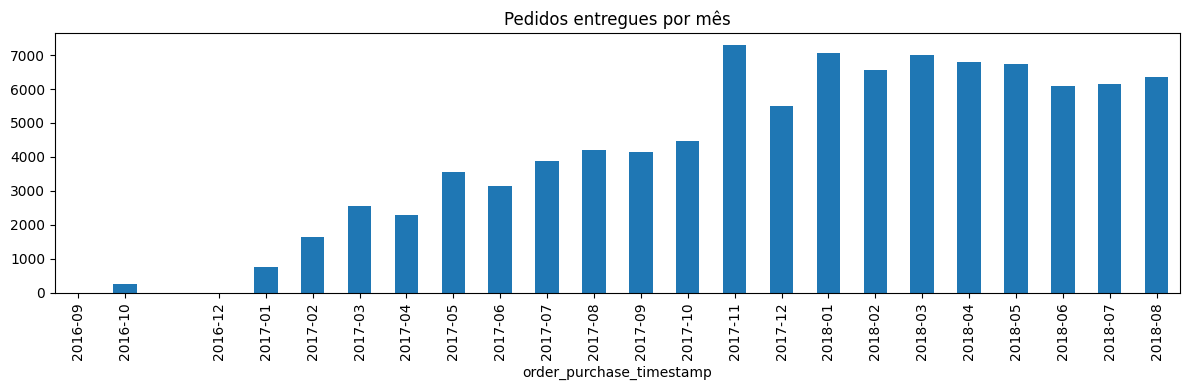

In [7]:
# Filtrar entregues e visualizar o período

# Base de pedidos válidos para o RFM
pedidos = orders[orders["order_status"] == "delivered"].copy()
print(f"Pedidos entregues: {len(pedidos):,} ({len(pedidos) / len(orders):.1%} da base)")

# Período coberto
print(f"\nPrimeira compra: {pedidos['order_purchase_timestamp'].min()}")
print(f"Última compra: {pedidos['order_purchase_timestamp'].max()}")

# Volume de pedidos por mês
vol_mes = pedidos["order_purchase_timestamp"].dt.to_period("M").value_counts().sort_index()
vol_mes.plot(kind="bar", figsize=(12, 4), title="Pedidos entregues por mês")
plt.tight_layout()
plt.show()

- Período da análise: jan/2017 a ago/2018. Os meses de 2016 têm volume residual e um mês sem dados.

In [8]:
# Prazo de entrega em dias (compra até entrega ao cliente)
pedidos["dias_entrega"] = (pedidos["order_delivered_customer_date"] - pedidos["order_purchase_timestamp"]).dt.days
print(pedidos["dias_entrega"].describe())

count   96470.00
mean       12.09
std         9.55
min         0.00
25%         6.00
50%        10.00
75%        15.00
max       209.00
Name: dias_entrega, dtype: float64


In [9]:
# Corte de período
pedidos = pedidos[pedidos["order_purchase_timestamp"] >= "2017-01-01"].copy()
print(f"Número de pedidos a partir de jan/2017: {len(pedidos):,}")

Número de pedidos a partir de jan/2017: 96,211


In [10]:
# Valor de cada pedido (soma dos pagamentos com o mesmo order_id)
valor_pedido = (
    payments.groupby("order_id", as_index=False)["payment_value"].sum()
    .rename(columns={"payment_value": "valor_pedido"})
)
print(f"Pedidos com valor: {len(valor_pedido):,} (antes eram {len(payments):,} linhas)")

Pedidos com valor: 99,440 (antes eram 103,886 linhas)


In [11]:
# Base final: pedido + valor + cliente real
base = (
    pedidos[["order_id", "customer_id", "order_purchase_timestamp"]]
    .merge(valor_pedido, on="order_id", how="inner", validate="one_to_one")
    .merge(customers[["customer_id", "customer_unique_id"]], on="customer_id", how="inner", validate="one_to_one")
)

print(f"\nBase final: {len(base):,} pedidos | {base['customer_unique_id'].nunique():,} clientes únicos")
print(f"Nulos: \n{base.isna().sum()}")
print(f"\n{base['valor_pedido'].describe()}")


Base final: 96,211 pedidos | 93,104 clientes únicos
Nulos: 
order_id                    0
customer_id                 0
order_purchase_timestamp    0
valor_pedido                0
customer_unique_id          0
dtype: int64

count   96211.00
mean      159.81
std       218.88
min         9.59
25%        61.88
50%       105.28
75%       176.26
max     13664.08
Name: valor_pedido, dtype: float64


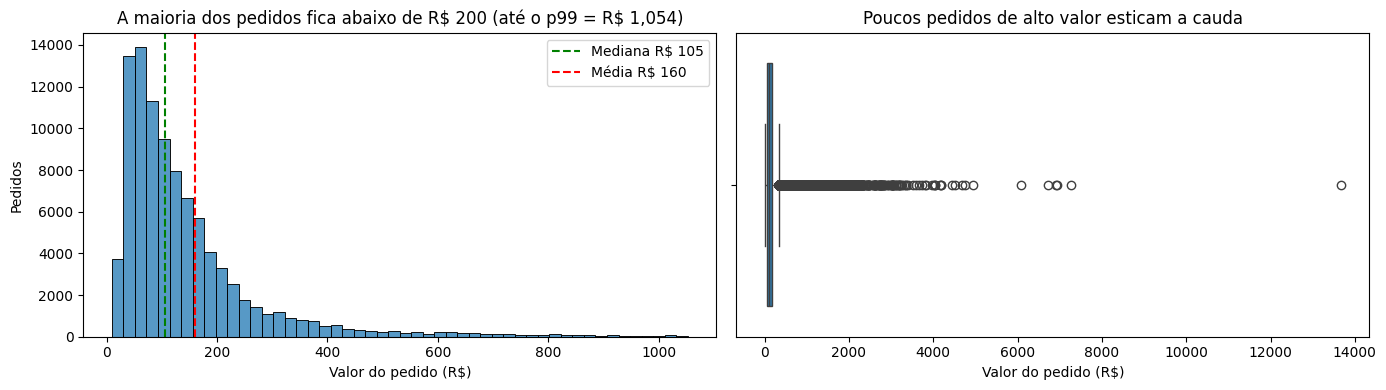

Pedidos acima do p99: 963 (1.0%)


In [12]:
valores = base["valor_pedido"]
p99 = valores.quantile(0.99)
mediana, media = valores.median(), valores.mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histograma: até o p99 para enxergar onde está a maioria
sns.histplot(valores[valores <= p99], bins=50, ax=axes[0])
axes[0].axvline(mediana, color="green", linestyle="--", label=f"Mediana R$ {mediana:,.0f}")
axes[0].axvline(media, color="red", linestyle="--", label=f"Média R$ {media:,.0f}")
axes[0].set_title(f"A maioria dos pedidos fica abaixo de R\\$ 200 (até o p99 = R\\$ {p99:,.0f})")
axes[0].set_xlabel("Valor do pedido (R$)")
axes[0].set_ylabel("Pedidos")
axes[0].legend()

# Boxplot: base completa, mostra a cauda de pedidos caros
sns.boxplot(x=valores, ax=axes[1])
axes[1].set_title("Poucos pedidos de alto valor esticam a cauda")
axes[1].set_xlabel("Valor do pedido (R$)")

plt.tight_layout()
plt.show()

print(f"Pedidos acima do p99: {(valores > p99).sum():,} ({(valores > p99).mean():.1%})")

- Valor do pedido com forte assimetria à direita (mediana R\$ 105, média R\$ 160). Valores altos são compras legítimas e foram mantidos.

In [13]:
# Cálculo de RFM (Recência, Frequência e Valor Monetário)

# Data de referência: dia seguinte à última compra da base
DATA_REF = base["order_purchase_timestamp"].max() + pd.Timedelta(days=1)
print(f"Data de referência: {DATA_REF.date()}")

# Uma linha por cliente real
rfm = (
    base.groupby("customer_unique_id")
    .agg(
        ultima_compra=("order_purchase_timestamp", "max"),
        frequencia=("order_id", "nunique"),
        monetario=("valor_pedido", "sum"),
    )
    .reset_index()
)

rfm["recencia"] = (DATA_REF - rfm["ultima_compra"]).dt.days

print(f"\nClientes: {len(rfm):,}")
print(rfm[["recencia", "frequencia", "monetario"]].describe())

# Distribuição de frequência
print("\nClientes por número de compras:")
freq = rfm["frequencia"].value_counts().sort_index()
print(pd.DataFrame({"clientes": freq, "% clientes": (freq / len(rfm) * 100).round(2)}))

Data de referência: 2018-08-30

Clientes: 93,104
       recencia  frequencia  monetario
count  93104.00    93104.00   93104.00
mean     236.70        1.03     165.15
std      150.94        0.21     226.38
min        1.00        1.00       9.59
25%      114.00        1.00      63.04
50%      218.00        1.00     107.78
75%      345.00        1.00     182.50
max      602.00       15.00   13664.08

Clientes por número de compras:
            clientes  % clientes
frequencia                      
1              90315       97.00
2               2562        2.75
3                180        0.19
4                 28        0.03
5                  9        0.01
6                  5        0.01
7                  3        0.00
9                  1        0.00
15                 1        0.00


- 97% dos clientes fizeram uma única compra; apenas 3% são recorrentes (2.789 clientes).
- Decisão: tratar como binário (Compra única vs Recorrente), pois quintis de frequência não diferenciam a base.

In [14]:
rfm["perfil"] = np.where(rfm["frequencia"] >= 2, "Recorrente", "Compra única")

resumo = (
    rfm.groupby("perfil")
    .agg(
        clientes=("customer_unique_id", "count"),
        receita=("monetario", "sum"),
        gasto_medio=("monetario", "mean"),
        recencia_mediana=("recencia", "median"),
    )
)

resumo["% clientes"] = (resumo["clientes"] / resumo["clientes"].sum() * 100).round(2)
resumo["% receita"] = (resumo["receita"] / resumo["receita"].sum() * 100).round(2)

display(resumo[["clientes", "% clientes", "receita", "% receita", "gasto_medio", "recencia_mediana"]])

,clientes,% clientes,receita,% receita,gasto_medio,recencia_mediana
perfil,,,,,,
Compra única,90315,97.00,14515120.88,94.40,160.72,219.00
Recorrente,2789,3.00,860754.56,5.60,308.62,199.00


- Recorrentes: 3% dos clientes e 5,6% da receita. Gastam o dobro no período porque compram mais vezes, não porque compram mais caro (R\$ 146 vs R\$ 161 por pedido).
- Reenquadramento: o problema de negócio é a falta da segunda compra.

In [15]:
# Notas de 1 a 5 por quintis (20% dos clientes em cada nota)
# Recência invertida: menos dias desde a última compra = nota maior
rfm["R_score"] = pd.qcut(rfm["recencia"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["M_score"] = pd.qcut(rfm["monetario"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

# Conferência: faixa de valores real de cada nota
print("Faixas de Recência (dias):")
print(rfm.groupby("R_score")["recencia"].agg(["min", "max", "count"]))
print("\nFaixas de Monetário (R$):")
print(rfm.groupby("M_score")["monetario"].agg(["min", "max", "count"]))

# Matriz R x M só para quem comprou uma única vez
unica = rfm[rfm["perfil"] == "Compra única"]
print("\nClientes de compra única por nota de R (linhas) e M (colunas):")
print(pd.crosstab(unica["R_score"], unica["M_score"], margins=True, margins_name="Total"))

Faixas de Recência (dias):
         min  max  count
R_score                 
1        380  602  18621
2        268  380  18621
3        177  268  18620
4         92  177  18621
5          1   92  18621

Faixas de Monetário (R$):
           min      max  count
M_score                       
1         9.59    55.24  18621
2        55.24    87.36  18621
3        87.36   132.65  18620
4       132.66   208.48  18621
5       208.48 13664.08  18621

Clientes de compra única por nota de R (linhas) e M (colunas):
M_score      1      2      3      4      5  Total
R_score                                          
1         3884   3893   3633   3296   3479  18185
2         3557   3977   3574   3477   3479  18064
3         3874   3605   3632   3691   3218  18020
4         3601   3494   3719   3749   3482  18045
5         3679   3497   3680   3712   3433  18001
Total    18595  18466  18238  17925  17091  90315


In [16]:
condicoes = [
    (rfm["R_score"] == 5) & (rfm["M_score"] >= 4),
    ((rfm["R_score"] == 5) & (rfm["M_score"] <= 3)) | ((rfm["R_score"] == 4) & (rfm["M_score"] >= 4)),
    rfm["R_score"].between(3, 4),
]
rotulos = ["1. Prioridade alta", "2. Prioridade média", "3. Prioridade baixa"]
rfm["prioridade"] = np.select(condicoes, rotulos, default="4. Fora da campanha")

# Recorrentes não entram nessa campanha: já fizeram a segunda compra
rfm.loc[rfm["perfil"] == "Recorrente", "prioridade"] = "0. Recorrente"

resumo_prior = (
    rfm.groupby("prioridade")
    .agg(
        clientes=("customer_unique_id", "count"),
        receita=("monetario", "sum"),
        gasto_medio=("monetario", "mean"),
        recencia_mediana=("recencia", "median"),
    )
)
resumo_prior["% clientes"] = (resumo_prior["clientes"] / resumo_prior["clientes"].sum() * 100).round(1)
display(resumo_prior)

,clientes,receita,gasto_medio,recencia_mediana,% clientes
prioridade,,,,,
0. Recorrente,2789,860754.56,308.62,199.00,3.00
1. Prioridade alta,7145,2150413.07,300.97,43.00,7.70
2. Prioridade média,18087,2982746.32,164.91,75.00,19.40
3. Prioridade baixa,28834,3523179.09,122.19,192.00,31.00
4. Fora da campanha,36249,5858782.40,161.63,381.00,38.90


- Prioridade alta: 7.145 clientes, recência mediana de 43 dias e gasto médio semelhante ao dos recorrentes.
- Clientes há mais de 268 dias sem comprar ficaram fora da campanha: concentram receita histórica, mas têm baixa chance de retorno.

In [17]:
# Premissa 1: valor real das segundas compras
base_ord = base.sort_values(["customer_unique_id", "order_purchase_timestamp"]).copy()
base_ord["n_pedido"] = base_ord.groupby("customer_unique_id").cumcount() + 1
segundas = base_ord.loc[base_ord["n_pedido"] == 2, "valor_pedido"]

ticket_2a = segundas.median()
print(f"Segundas compras observadas: {len(segundas):,}")
print(f"Valor da 2ª compra | média R$ {segundas.mean():,.2f} | mediana R$ {ticket_2a:,.2f}")

# Premissa 2: cenários de conversão
TAXAS = [0.02, 0.05, 0.10]

clientes_prior = (
    rfm.loc[rfm["prioridade"].str[0].isin(["1", "2", "3"]), "prioridade"]
    .value_counts()
    .sort_index()
)

cenarios = pd.DataFrame(
    {f"Conversão {t:.0%}": clientes_prior * t * ticket_2a for t in TAXAS}
)
cenarios.loc["Total"] = cenarios.sum()
print("\nReceita potencial da segunda compra (R$):")
display(cenarios.round(0))

Segundas compras observadas: 2,789
Valor da 2ª compra | média R$ 146.79 | mediana R$ 100.53

Receita potencial da segunda compra (R$):


,Conversão 2%,Conversão 5%,Conversão 10%
prioridade,,,
1. Prioridade alta,14366.00,35914.00,71829.00
2. Prioridade média,36366.00,90914.00,181829.00
3. Prioridade baixa,57974.00,144934.00,289868.00
Total,108705.00,271763.00,543525.00


## Premissas da avaliação

- Valor da 2ª compra: mediana das segundas compras reais (R\$ 100,53), escolha conservadora.
- Taxas de conversão: cenários hipotéticos, decrescentes por prioridade.
- Ganho real deve ser medido com grupo de controle (teste A/B), pois parte dos clientes voltaria sem campanha.

In [18]:
# Cenários com taxas decrescentes por prioridade (premissas, não dados)
CENARIOS = {
    "Pessimista": {"1. Prioridade alta": 0.05, "2. Prioridade média": 0.03, "3. Prioridade baixa": 0.01},
    "Moderado":   {"1. Prioridade alta": 0.10, "2. Prioridade média": 0.05, "3. Prioridade baixa": 0.02},
    "Otimista":   {"1. Prioridade alta": 0.15, "2. Prioridade média": 0.08, "3. Prioridade baixa": 0.03},
}

linhas = []
for cenario, taxas in CENARIOS.items():
    for prior, taxa in taxas.items():
        n = clientes_prior[prior]
        linhas.append({
            "cenario": cenario,
            "prioridade": prior,
            "clientes": n,
            "taxa": taxa,
            "receita": n * taxa * ticket_2a,
            "receita_por_cliente": taxa * ticket_2a,
        })

impacto = pd.DataFrame(linhas)

print("Receita potencial por cenário (R$):")
display(impacto.pivot(index="prioridade", columns="cenario", values="receita")
        [["Pessimista", "Moderado", "Otimista"]].round(0))

print("\nReceita esperada por cliente impactado, cenário moderado (R$):")
display(impacto.loc[impacto["cenario"] == "Moderado",
                    ["prioridade", "clientes", "taxa", "receita_por_cliente"]].round(2))

Receita potencial por cenário (R$):


cenario,Pessimista,Moderado,Otimista
prioridade,,,
1. Prioridade alta,35914.00,71829.00,107743.00
2. Prioridade média,54549.00,90914.00,145463.00
3. Prioridade baixa,28987.00,57974.00,86960.00



Receita esperada por cliente impactado, cenário moderado (R$):


,prioridade,clientes,taxa,receita_por_cliente
3,1. Prioridade alta,7145,0.10,10.05
4,2. Prioridade média,18087,0.05,5.03
5,3. Prioridade baixa,28834,0.02,2.01


- Cenário moderado: receita potencial de ~R\$ 221 mil; prioridade alta rende R\$ 10,05 por cliente impactado, 5x a prioridade baixa.
- Limitação: valores são receita, não margem. O custo por contato deve ser comparado à margem de cada grupo.

In [19]:
# 1. Staging: base RFM completa em Parquet (para reuso no notebook e em análises futuras)
rfm.to_parquet(PASTA_PROCESSED / "rfm_clientes.parquet", index=False)

# 2. Lista da campanha: prioridades 1 e 2, ordenada para o time de CRM
COLUNAS_LISTA = {
    "customer_unique_id": "id_cliente",
    "prioridade": "prioridade",
    "R_score": "nota_recencia",
    "M_score": "nota_valor",
    "recencia": "dias_desde_ultima_compra",
    "ultima_compra": "data_ultima_compra",
    "monetario": "valor_gasto",
}

lista_campanha = (
    rfm.loc[rfm["prioridade"].str[0].isin(["1", "2"]), list(COLUNAS_LISTA)]
    .rename(columns=COLUNAS_LISTA)
    .sort_values(["prioridade", "nota_valor", "dias_desde_ultima_compra"],
                 ascending=[True, False, True])
)
lista_campanha["data_ultima_compra"] = lista_campanha["data_ultima_compra"].dt.date

# CSV no padrão do Excel brasileiro
lista_campanha.to_csv(
    PASTA_PROCESSED / "lista_campanha_segunda_compra.csv",
    index=False, sep=";", decimal=",", encoding="utf-8-sig",
)

# 3. Conferência: relê os arquivos salvos
check = pd.read_csv(PASTA_PROCESSED / "lista_campanha_segunda_compra.csv", sep=";", decimal=",")
print(f"Lista salva: {len(check):,} clientes")
print(check["prioridade"].value_counts().sort_index())
display(check.head())

Lista salva: 25,232 clientes
prioridade
1. Prioridade alta      7145
2. Prioridade média    18087
Name: count, dtype: int64


,id_cliente,prioridade,nota_recencia,nota_valor,dias_desde_ultima_compra,data_ultima_compra,valor_gasto
0,2cbb27285e259123d5b9aac321b7085e,1. Prioridade alta,5,5,1,2018-08-28,216.58
1,44d111bdc55faca551ef91cb74a444d8,1. Prioridade alta,5,5,1,2018-08-28,259.81
2,55cfdb1ec3c5bf60d9ccc0d5f276f8a9,1. Prioridade alta,5,5,1,2018-08-28,260.50
3,5c58de6fb80e93396e2f35642666b693,1. Prioridade alta,5,5,1,2018-08-29,510.96
4,83176537f63ef9c7510572006c85ac50,1. Prioridade alta,5,5,1,2018-08-28,712.90


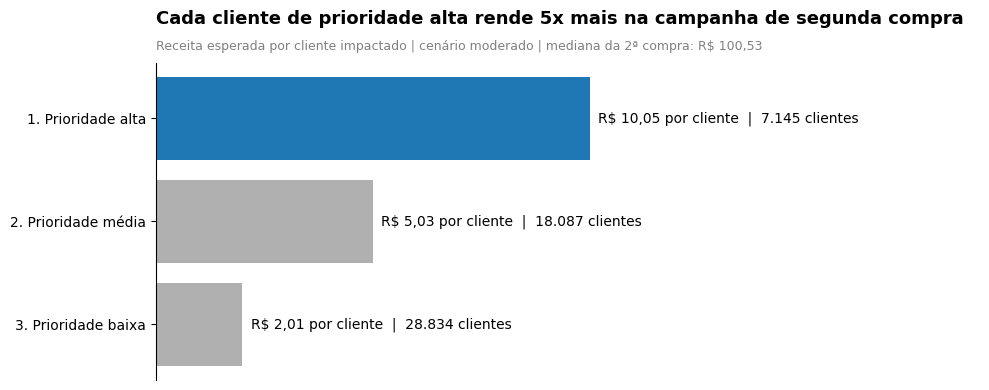

In [20]:
def fmt_br(valor, casas=2):
    """Formata número no padrão brasileiro: 1.234,56"""
    return f"{valor:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

dados = impacto.loc[impacto["cenario"] == "Moderado"].sort_values("prioridade", ascending=False)

# Destaque só na prioridade alta; o resto em cinza
cores = ["#1f77b4" if p.startswith("1") else "#b0b0b0" for p in dados["prioridade"]]

fig, ax = plt.subplots(figsize=(10, 4))
barras = ax.barh(dados["prioridade"], dados["receita_por_cliente"], color=cores)

# Rótulo em cada barra: valor por cliente e tamanho do grupo
for barra, (_, linha) in zip(barras, dados.iterrows()):
    ax.text(
        barra.get_width() + 0.2, barra.get_y() + barra.get_height() / 2,
        f"R\\$ {fmt_br(linha['receita_por_cliente'])} por cliente  |  {fmt_br(linha['clientes'], 0)} clientes",
        va="center", fontsize=10,
    )

ax.set_title("Cada cliente de prioridade alta rende 5x mais na campanha de segunda compra",
             loc="left", fontsize=13, fontweight="bold", pad=28)
ax.text(0, 1.04,
        f"Receita esperada por cliente impactado | cenário moderado | mediana da 2ª compra: R\\$ {fmt_br(ticket_2a)}",
        transform=ax.transAxes, fontsize=9, color="gray")

ax.set_xlabel("")
ax.set_xticks([])
ax.set_xlim(0, dados["receita_por_cliente"].max() * 1.9)
for lado in ["top", "right", "bottom"]:
    ax.spines[lado].set_visible(False)

plt.tight_layout()

# Salva para o post e para a apresentação
PASTA_FIG = PASTA_RAIZ / "figures"
PASTA_FIG.mkdir(exist_ok=True)
fig.savefig(PASTA_FIG / "receita_por_cliente_prioridade.png", dpi=150, bbox_inches="tight")
plt.show()